# EDA 1 — Impressions: slates, clicks, position and feedback semantics

Training split of **MIND-small** (95,071 impressions, 9 to 12 Nov 2019), read from the processed files written by
`1_Data_Preparation/1. data_preparation.ipynb`:

* `impressions_train.parquet`: one row per impression (`slate_len`, `n_clicks`, `n_negatives`, `history_len`, ...)
* `candidates_train.parquet`: one row per (impression, candidate) with `position`, `news_code`, `clicked`
* `news_catalogue.parquet`: article metadata

An **impression** is one slate of candidate articles shown to one user. Each candidate carries a label: **1 for click, 0 for no click**.
The order of candidates was shuffled by Microsoft before release.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Project root = the folder that contains 1_Data_Preparation/processed (written by 1. data_preparation.ipynb)
CODE_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "run_all.py").is_file()
)
ROOT = (
    Path(os.environ.get("NEWSREC_ROOT", CODE_ROOT / "runs/mindsmall-epoch"))
    .expanduser()
    .resolve()
)
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
FIG_DIR = ROOT / "2_EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/anhminhhoang/Documents/GitHub/BT4222-Group-6-


In [2]:
# 1. Load the three processed tables for the training split
imp = pd.read_parquet(PROCESSED / "impressions_train.parquet").drop(columns="history")
cand = pd.read_parquet(PROCESSED / "candidates_train.parquet")
news = pd.read_parquet(
    PROCESSED / "news_catalogue.parquet",
    columns=["news_code", "category", "in_news_train"],
)

# 2. Headline counts
n_imp = len(imp)
n_users = imp["user_code"].nunique()
n_exp = len(cand)
n_clicks = int(cand["clicked"].sum())
print("Impressions:", n_imp)
print("Users:", n_users)
print("Candidate exposures:", n_exp)
print("Clicks:", n_clicks)
print(f"Overall CTR: {100 * n_clicks / n_exp:.2f}%")
print("Time window:", imp["timestamp"].min(), "->", imp["timestamp"].max())

Impressions: 95071
Users: 40148
Candidate exposures: 3389342
Clicks: 141558
Overall CTR: 4.18%
Time window: 2019-11-09 00:00:19 -> 2019-11-12 23:59:25


# 1. Slate length and clicks per impression

## 1.1 Slate length
Slate length is the number of candidates in an impression. From the results below:
* Slates run from **2 to 297** candidates; the median is **23** and the mean 36. 30% of slates have at most 10 candidates, 8% more than 100.
* The spikes at **2, 4, 7, 3 and 10** suggest a small number of fixed page templates rather than a continuous ranking cutoff.

In [3]:
# 1. Distribution of slate length
slate = imp["slate_len"]
print(slate.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))

# 2. Share of impressions per slate length
pct = 100 * slate.value_counts(normalize=True).sort_index()
print("\nMost common slate lengths (% of impressions):")
print(pct.nlargest(5).round(2))
print(f"\n<= 10 candidates: {pct[pct.index <= 10].sum():.1f}%")
print(f"<= 25 candidates: {pct[pct.index <= 25].sum():.1f}%")
print(f"> 100 candidates: {pct[pct.index > 100].sum():.1f}%")

count    95071.0
mean        35.7
std         37.7
min          2.0
5%           2.0
25%          9.0
50%         23.0
75%         49.0
95%        115.0
max        297.0
Name: slate_len, dtype: float64

Most common slate lengths (% of impressions):
slate_len
2     7.15
4     5.43
7     3.85
3     3.15
10    3.08
Name: proportion, dtype: float64

<= 10 candidates: 30.0%
<= 25 candidates: 53.2%
> 100 candidates: 7.6%


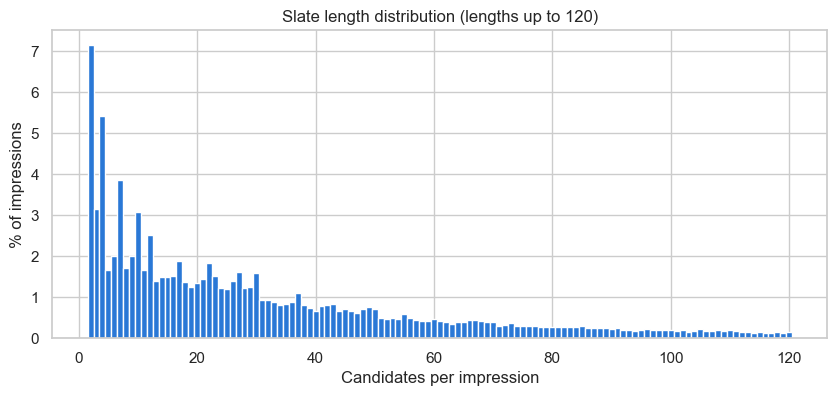

In [4]:
# Plot
short = pct[pct.index <= 120]
plt.figure(figsize=(10, 4))
plt.bar(short.index, short.values, width=1.0)
plt.title("Slate length distribution (lengths up to 120)")
plt.xlabel("Candidates per impression")
plt.ylabel("% of impressions")
plt.savefig(FIG_DIR / "imp_01_slate_length.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.2 Clicks per impression and the one-click property
* **No impression has zero clicks**: the release only kept impressions that ended in a click. 73% contain exactly one click, mean 1.49.
* Because clicks barely grow with slate size, CTR per candidate is close to **1 / slate length** (Spearman correlation between slate
  length and impression CTR is −0.90).

**Model Implications**
* The 4.18% CTR is a click-conditioned number, only comparable within this log, not a platform CTR.
* `slate_len` predicts the label by construction and is **excluded as a feature**; ranking must be evaluated **per impression**.

In [5]:
# 1. Number of clicks per impression
cpi = 100 * imp["n_clicks"].value_counts(normalize=True).sort_index()
print("Impressions with 0 clicks:", int((imp["n_clicks"] == 0).sum()))
print("% of impressions by number of clicks:")
print(cpi.head(6).round(2))
print(f"Mean clicks per impression: {n_clicks / n_imp:.2f}")

# 2. CTR and mean clicks by slate length
by_len = (
    imp.groupby("slate_len")
    .agg(impressions=("n_clicks", "size"), clicks=("n_clicks", "sum"))
    .reset_index()
)
by_len["ctr"] = 100 * by_len.clicks / (by_len.slate_len * by_len.impressions)
by_len["mean_clicks"] = by_len.clicks / by_len.impressions
imp_ctr = imp["n_clicks"] / imp["slate_len"]
rho = stats.spearmanr(imp["slate_len"], imp_ctr).statistic
print(f"\nSpearman(slate length, impression CTR) = {rho:.2f}")
print(
    by_len[by_len.slate_len.isin([2, 5, 10, 25, 50, 100, 200])]
    .round(2)
    .to_string(index=False)
)

Impressions with 0 clicks: 0
% of impressions by number of clicks:
n_clicks
1    73.35
2    15.82
3     5.77
4     2.45
5     1.21
6     0.59
Name: proportion, dtype: float64
Mean clicks per impression: 1.49

Spearman(slate length, impression CTR) = -0.90
 slate_len  impressions  clicks   ctr  mean_clicks
         2         6799    6799 50.00         1.00
         5         1569    1636 20.85         1.04
        10         2925    3608 12.34         1.23
        25         1144    1571  5.49         1.37
        50          668    1220  3.65         1.83
       100          192     418  2.18         2.18
       200            6      15  1.25         2.50


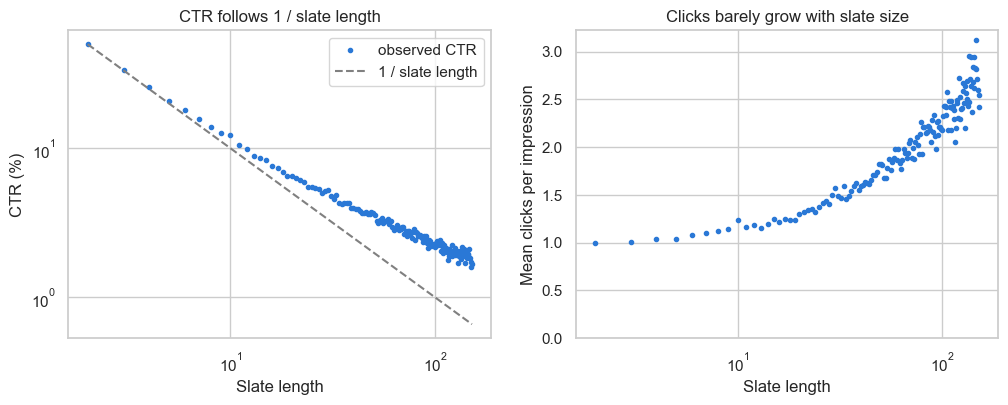

In [6]:
# Plot: observed CTR against the 1 / slate-length reference, and mean clicks
d = by_len[by_len.impressions >= 50]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(d.slate_len, d.ctr, "o", ms=3, label="observed CTR")
ax[0].plot(d.slate_len, 100 / d.slate_len, "--", color="grey", label="1 / slate length")
ax[0].set(xscale="log", yscale="log", xlabel="Slate length", ylabel="CTR (%)")
ax[0].set_title("CTR follows 1 / slate length")
ax[0].legend()
ax[1].plot(d.slate_len, d.mean_clicks, "o", ms=3)
ax[1].set(
    xscale="log",
    ylim=(0, None),
    xlabel="Slate length",
    ylabel="Mean clicks per impression",
)
ax[1].set_title("Clicks barely grow with slate size")
plt.savefig(FIG_DIR / "imp_02_ctr_by_slate_length.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Position in the slate

Position is the 1-based order of a candidate in the impression string. Pooled over all impressions CTR drops from 11.6% at position 1 to
1.9% at position 100, which looks like position bias. Two checks show it is a **composition effect**:
* A null model that spreads each impression's clicks evenly over its own slate (so it only uses the mix of slate lengths) reproduces the
  pooled curve within **0.3 percentage points**.
* With slate length held fixed (7, 10, 12, 25) CTR is flat across positions and a chi-square test of uniform clicks is not significant
  (p between 0.17 and 0.63; the spread is wider than on MIND-large simply because each length has a few thousand impressions).

**Model Implications**
* The stored order carries **no display-rank information** (MIND documents that it was shuffled). `position` is not a feature and no
  position-bias correction is needed.

In [7]:
# 1. Pooled CTR by absolute position
pos = (
    cand.groupby("position")
    .agg(exposures=("clicked", "size"), clicks=("clicked", "sum"))
    .reset_index()
)
pos["ctr"] = 100 * pos.clicks / pos.exposures

# 2. Null model: if each impression's clicks were spread evenly over its own slate, the CTR at position p is
#    sum over impressions with slate_len >= p of (clicks / slate_len), divided by the number of such impressions
L = by_len.slate_len.values
imps = np.zeros(L.max() + 1)
clk = np.zeros(L.max() + 1)
imps[L] = by_len.impressions.values
clk[L] = by_len.clicks.values
share = clk / np.maximum(np.arange(L.max() + 1), 1)
imps_ge = np.cumsum(imps[::-1])[::-1]
share_ge = np.cumsum(share[::-1])[::-1]
pos["null_ctr"] = 100 * share_ge[pos.position] / imps_ge[pos.position]
print(pos[pos.position.isin([1, 5, 10, 20, 50, 100])].round(2).to_string(index=False))
big = pos[pos.exposures >= 10_000]
gap_pp = (big.ctr - big.null_ctr).abs().max()
print(
    f"\nLargest |observed - null| gap (positions with >= 10k exposures): {gap_pp:.2f} pp"
)

# 3. CTR by position with slate length held fixed, plus a chi-square test of uniform clicks
fixed = cand.merge(imp[["impression_uid", "slate_len"]], on="impression_uid")
fixed = fixed[fixed.slate_len.isin([7, 10, 12, 25])]
fixed = fixed.groupby(["slate_len", "position"]).agg(
    exposures=("clicked", "size"), clicks=("clicked", "sum")
)
fixed = fixed.reset_index()
fixed["ctr"] = 100 * fixed.clicks / fixed.exposures
print("\nCTR by position with slate length held fixed:")
for Lf, g in fixed.groupby("slate_len"):
    chi = stats.chisquare(g.clicks.values)
    print(
        f"  length {Lf:>2}: n = {g.exposures.iloc[0]:>6,} impressions, "
        f"CTR {g.ctr.min():.2f}% to {g.ctr.max():.2f}%, chi2 p = {chi.pvalue:.2f}"
    )

 position  exposures  clicks   ctr  null_ctr
        1      95071   11005 11.58     11.61
        5      80112    5362  6.69      6.60
       10      69448    3535  5.09      5.14
       20      52650    2003  3.80      3.88
       50      23414     553  2.36      2.61
      100       7371     141  1.91      1.98

Largest |observed - null| gap (positions with >= 10k exposures): 0.26 pp

CTR by position with slate length held fixed:
  length  7: n =  3,661 impressions, CTR 14.67% to 17.02%, chi2 p = 0.17
  length 10: n =  2,925 impressions, CTR 11.42% to 13.30%, chi2 p = 0.58
  length 12: n =  2,392 impressions, CTR 9.11% to 11.16%, chi2 p = 0.63
  length 25: n =  1,144 impressions, CTR 4.11% to 7.08%, chi2 p = 0.42


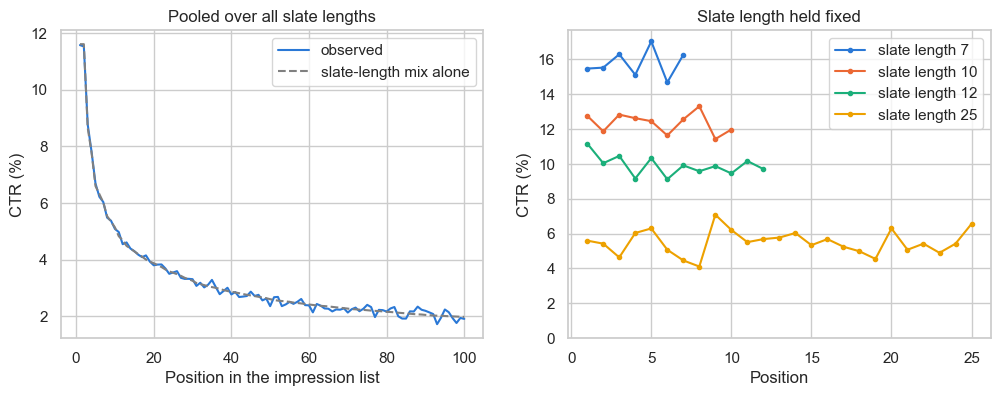

In [8]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d = pos[pos.position <= 100]
ax[0].plot(d.position, d.ctr, label="observed")
ax[0].plot(d.position, d.null_ctr, "--", color="grey", label="slate-length mix alone")
ax[0].set(
    xlabel="Position in the impression list",
    ylabel="CTR (%)",
    title="Pooled over all slate lengths",
)
ax[0].legend()
for Lf, g in fixed.groupby("slate_len"):
    ax[1].plot(g.position, g.ctr, marker="o", ms=3, label=f"slate length {Lf}")
ax[1].set(
    ylim=(0, None), xlabel="Position", ylabel="CTR (%)", title="Slate length held fixed"
)
ax[1].legend()
plt.savefig(FIG_DIR / "imp_03_position.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Exposure-to-click funnel and what the labels mean

MIND records exactly two stages: an article is **exposed** in a slate, and it is **clicked or not**. There is no dwell time or share signal.
* 3.39 M exposures produce 141,558 clicks (4.18%). Every impression and every user has at least one click (the click filter above).
* Of the 43,370 articles in the training news file only **13,536 were ever shown** and 5,046 ever clicked; the rest exist only in user
  histories. MSN's own candidate generation chose what was shown, and labels exist only for those pairs.

**Model Implications**
* Clicked = positive; shown and not clicked = explicit negative; in the history = past positive (input only); **everything else is
  unobserved, not negative**. The re-ranker trains on logged slates; the retrieval stage can only be scored against known clicks.

In [9]:
# 1. Article-level funnel
shown = cand["news_code"].nunique()
clicked_articles = cand.loc[cand.clicked == 1, "news_code"].nunique()
catalogue = int(news["in_news_train"].sum())

# 2. History entries, counted once per user (the supplied history is identical across a user's impressions)
user_hist = pd.read_parquet(
    PROCESSED / "impressions_train.parquet", columns=["user_code", "history_len"]
)
history_entries = int(user_hist.drop_duplicates("user_code")["history_len"].sum())

print("Funnel (training split)")
print(f"  exposures                     {n_exp:>14,}")
print(
    f"  clicks                        {n_clicks:>14,}   ({100 * n_clicks / n_exp:.2f}% of exposures)"
)
print(f"  impressions                   {n_imp:>14,}   (100% with >= 1 click)")
print(f"  articles in news file         {catalogue:>14,}")
print(
    f"  articles shown at least once  {shown:>14,}   ({100 * shown / catalogue:.1f}% of the news file)"
)
print(
    f"  articles clicked at least once{clicked_articles:>14,}   ({100 * clicked_articles / shown:.1f}% of shown)"
)
print(f"  users                         {n_users:>14,}   (100% with >= 1 click)")

# 3. Classification of (user, article) pairs
unobserved = n_users * catalogue - n_exp - history_entries
print("\n(user, article) pairs")
print(f"  shown and clicked (y = 1)             {n_clicks:>14,}")
print(f"  shown, not clicked (y = 0)            {n_exp - n_clicks:>14,}")
print(f"  in the supplied history (input only)  {history_entries:>14,}")
print(f"  unobserved (label unknown)            {unobserved:>14,}")

Funnel (training split)
  exposures                          3,389,342
  clicks                               141,558   (4.18% of exposures)
  impressions                           95,071   (100% with >= 1 click)
  articles in news file                 43,370
  articles shown at least once          13,536   (31.2% of the news file)
  articles clicked at least once         5,046   (37.3% of shown)
  users                                 40,148   (100% with >= 1 click)

(user, article) pairs
  shown and clicked (y = 1)                    141,558
  shown, not clicked (y = 0)                 3,247,784
  in the supplied history (input only)         806,306
  unobserved (label unknown)             1,737,023,112


# 4. Label imbalance and negative sampling

* There are **22.9 explicit negatives per positive** overall and 16 in the median impression; 16% of impressions have fewer than 4 negatives.
* The agreed scheme (K = 4 unclicked articles per click from the same impression, one seeded draw without replacement) leaves at least
  **84%** of the explicit negatives unused; K = 8 and K = 16 leave 70% and 49% at the same number of training rows.

**Model Implications**
* Keep K = 4 as the baseline, report the discarded share, and run K = 8 / 16 as a sensitivity check. Exposed negatives are the right
  negatives for the re-ranker: they passed the same editorial filter as the positives and are the only pairs with a label.

In [10]:
# 1. Negatives per positive
ratio = imp["n_negatives"] / imp["n_clicks"]
n_neg = n_exp - n_clicks
print(f"Negatives per positive, pooled: {n_neg / n_clicks:.1f}")
print(
    f"Negatives per positive, median impression: {ratio.median():.1f} "
    f"(IQR {ratio.quantile(0.25):.1f} to {ratio.quantile(0.75):.1f})"
)
print(
    f"Impressions with fewer than 4 negatives: {100 * (imp['n_negatives'] < 4).mean():.1f}%"
)

# 2. What a draw of K negatives per positive keeps and discards
print(
    "\nK | negatives used per positive | explicit negatives never used | positives in impressions with < K negatives"
)
sweep = []
for K in [4, 8, 16, 24, 32]:
    used = int(np.minimum(imp["n_negatives"], K * imp["n_clicks"]).sum())
    short = int(imp.loc[imp["n_negatives"] < K, "n_clicks"].sum())
    unused_pct = 100 * (1 - used / n_neg)
    sweep.append((K, unused_pct))
    print(
        f"  K = {K:>2}: {used / n_clicks:5.2f} | {unused_pct:4.0f}% | {100 * short / n_clicks:4.1f}%"
    )

Negatives per positive, pooled: 22.9
Negatives per positive, median impression: 16.0 (IQR 6.0 to 32.5)
Impressions with fewer than 4 negatives: 15.8%

K | negatives used per positive | explicit negatives never used | positives in impressions with < K negatives
  K =  4:  3.73 |   84% | 10.9%
  K =  8:  6.89 |   70% | 18.1%
  K = 16: 11.65 |   49% | 30.4%
  K = 24: 14.83 |   35% | 41.1%
  K = 32: 16.96 |   26% | 50.9%


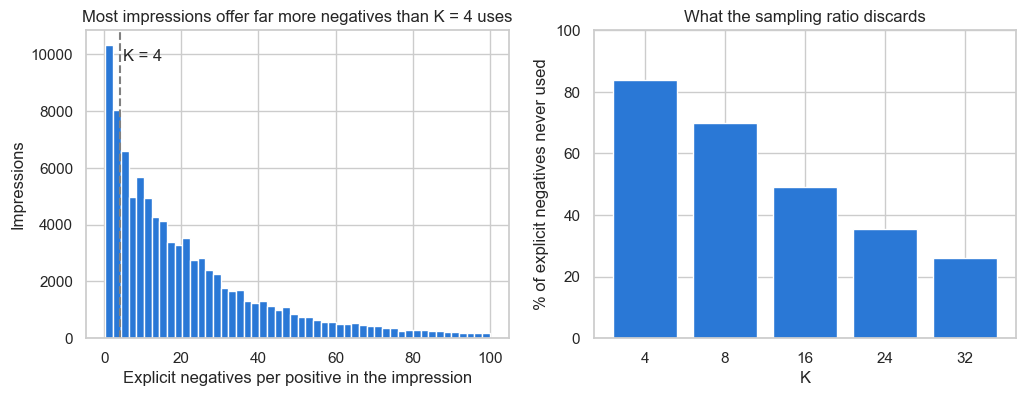

In [11]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(ratio[ratio <= 100], bins=50)
ax[0].axvline(4, color="grey", ls="--")
ax[0].text(5, ax[0].get_ylim()[1] * 0.9, "K = 4")
ax[0].set(
    xlabel="Explicit negatives per positive in the impression", ylabel="Impressions"
)
ax[0].set_title("Most impressions offer far more negatives than K = 4 uses")
ax[1].bar([str(k) for k, _ in sweep], [v for _, v in sweep])
ax[1].set(xlabel="K", ylabel="% of explicit negatives never used", ylim=(0, 100))
ax[1].set_title("What the sampling ratio discards")
plt.savefig(FIG_DIR / "imp_04_negative_sampling.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Repeat exposure and history overlap

* **14% of exposures** re-show an article the same user already saw inside the window. CTR is 4.4% on first exposure, **2.6%** on a second
  exposure after the user passed it over, 5.2% after an earlier click; third or later exposures fall further.
* Candidates already in the user's supplied history are rare (0.35% of candidates, 0.7% of clicks) and are clicked at 7.9% when re-shown.

**Model Implications**
* "Previously shown and not clicked" is a usable, time-causal feature (`prior_exposure_count` with its outcome).
* History overlap is too small to be a leakage concern; the rows are kept.

In [12]:
# 1. Rank each (user, article) pair's exposures in time; prior_clicks = clicks on earlier exposures of the same pair
rep = cand.sort_values(["user_code", "news_code", "timestamp", "impression_uid"]).copy()
pair = rep.groupby(["user_code", "news_code"], sort=False)
rep["rank"] = pair.cumcount() + 1
rep["prior_clicks"] = pair["clicked"].cumsum() - rep["clicked"]
rep = rep[rep["rank"] >= 2]
n_repeat = len(rep)

# 2. CTR by exposure rank and earlier outcome
rep["exposure"] = np.where(rep["rank"] == 2, "2nd exposure", "3rd or later")
rep["history"] = np.where(
    rep["prior_clicks"] > 0, "clicked before", "passed over before"
)
tbl = (
    rep.groupby(["exposure", "history"])
    .agg(exposures=("clicked", "size"), clicks=("clicked", "sum"))
    .reset_index()
)
first = pd.DataFrame(
    [
        {
            "exposure": "1st exposure",
            "history": "-",
            "exposures": n_exp - n_repeat,
            "clicks": n_clicks - tbl.clicks.sum(),
        }
    ]
)
tbl = pd.concat([first, tbl], ignore_index=True)
tbl["ctr"] = (100 * tbl.clicks / tbl.exposures).round(2)
tbl["share_of_exposures"] = (100 * tbl.exposures / n_exp).round(2)
print(f"Repeat exposures: {n_repeat:,} ({100 * n_repeat / n_exp:.1f}% of exposures)")
print(tbl.to_string(index=False))
del rep

Repeat exposures: 466,151 (13.8% of exposures)
    exposure            history  exposures  clicks  ctr  share_of_exposures
1st exposure                  -    2923191  129669 4.44               86.25
2nd exposure     clicked before      16047     828 5.16                0.47
2nd exposure passed over before     348091    9081 2.61               10.27
3rd or later     clicked before       7789     235 3.02                0.23
3rd or later passed over before      94224    1745 1.85                2.78


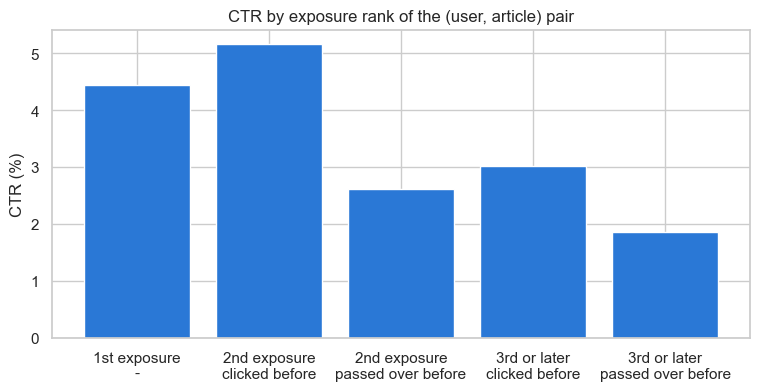

In [13]:
# Plot
plt.figure(figsize=(9, 4))
plt.bar(tbl.exposure + "\n" + tbl.history, tbl.ctr)
plt.title("CTR by exposure rank of the (user, article) pair")
plt.ylabel("CTR (%)")
plt.savefig(FIG_DIR / "imp_05_repeat_exposure.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# 1. Explode the supplied history of each impression into (impression_uid, news_code) pairs
hist = pd.read_parquet(
    PROCESSED / "impressions_train.parquet", columns=["impression_uid", "history"]
)
hist["news_code"] = hist["history"].fillna("").str.split()
hist = hist.explode("news_code").dropna(subset=["news_code"])
hist["news_code"] = hist["news_code"].str[1:].astype("int32")
hist = hist.drop_duplicates(
    ["impression_uid", "news_code"]
)  # a history can list the same article twice

# 2. Candidates that are already in the user's supplied history
overlap = cand.merge(
    hist[["impression_uid", "news_code"]], on=["impression_uid", "news_code"]
)
overlap_clicks = int(overlap.clicked.sum())
print(
    f"Candidates already in the user's history: {len(overlap):,} ({100 * len(overlap) / n_exp:.2f}% of candidates)"
)
print(
    f"Clicked candidates already in the history: {overlap_clicks:,} ({100 * overlap_clicks / n_clicks:.2f}% of clicks)"
)
print(
    f"CTR when an article from the history is re-shown: {100 * overlap.clicked.mean():.1f}%"
)
del hist, overlap

Candidates already in the user's history: 11,939 (0.35% of candidates)
Clicked candidates already in the history: 939 (0.66% of clicks)
CTR when an article from the history is re-shown: 7.9%


# 6. Slate composition: does category diversity or a stand-out article change clicks?

Two naive patterns look strong: diverse slates collect more clicks, and an article that is the only one of its category in the slate has a
much higher CTR. Both have to be checked at a **fixed slate length**, because longer slates collect more clicks and have lower per-article CTR.
* At a fixed length (10, 20, 30, 50) mean clicks per slate are **flat** across the number of categories.
* At a fixed length a unique-category article is **not** clicked more than the others (length 10: 11.9% vs 12.6%).

**Model Implications**
* Slate-level diversity and stand-out flags carry little independent signal; they are low-priority features. The whole log is
  conditioned on a click, so whether a diverse slate converts a non-clicking visit cannot be seen here.

In [15]:
# 1. Per (impression, category): how many candidates share the category and how many of them were clicked
cc = cand.merge(news[["news_code", "category"]], on="news_code")
cc = cc.merge(imp[["impression_uid", "slate_len"]], on="impression_uid")
slate_cat = (
    cc.groupby(["impression_uid", "category"], observed=True)
    .agg(
        k=("clicked", "size"),
        cat_clicks=("clicked", "sum"),
        slate_len=("slate_len", "first"),
    )
    .reset_index()
)

# 2. Per impression: number of distinct categories (capped at 12) and clicks
per_slate = (
    slate_cat.groupby("impression_uid")
    .agg(
        n_cats=("k", "size"),
        slate_len=("slate_len", "first"),
        n_clicks=("cat_clicks", "sum"),
    )
    .reset_index()
)
per_slate["n_cats"] = per_slate["n_cats"].clip(upper=12)

# 3. Naive view (all slates) versus slates of a fixed length
naive = per_slate.groupby("n_cats").agg(
    slates=("n_clicks", "size"),
    mean_slate_len=("slate_len", "mean"),
    mean_clicks=("n_clicks", "mean"),
)
print("All slates (note how mean slate length rises with the number of categories):")
print(naive.round(2))
fixed_div = per_slate[per_slate.slate_len.isin([10, 20, 30, 50])]
fixed_div = fixed_div.groupby(["slate_len", "n_cats"]).agg(
    slates=("n_clicks", "size"), mean_clicks=("n_clicks", "mean")
)
fixed_div = fixed_div.reset_index()
fixed_div = fixed_div[fixed_div.slates >= 100]
print("\nMean clicks per slate at fixed slate length:")
print(
    fixed_div.pivot(index="n_cats", columns="slate_len", values="mean_clicks").round(2)
)

# 4. Stand-out articles: CTR of candidates whose category is unique in the slate vs shared, at exact slate lengths
role = slate_cat[slate_cat.slate_len.isin([10, 25, 50, 100])].copy()
role["role"] = np.where(role.k == 1, "unique category", "shared category")
role = (
    role.groupby(["slate_len", "role"])
    .agg(exposures=("k", "sum"), clicks=("cat_clicks", "sum"))
    .reset_index()
)
role["ctr"] = 100 * role.clicks / role.exposures
role_ctr = role.pivot(index="slate_len", columns="role", values="ctr")
print(
    "\nCTR (%) of unique-category vs shared-category candidates at fixed slate length:"
)
print(role_ctr.round(2))

All slates (note how mean slate length rises with the number of categories):
        slates  mean_slate_len  mean_clicks
n_cats                                     
1         2134            2.98         1.01
2         8089            2.78         1.01
3         6546            4.93         1.05
4         6280            7.82         1.12
5         5432           10.56         1.15
6         4441           13.74         1.22
7         5352           18.17         1.28
8         6539           24.00         1.36
9         7216           32.12         1.46
10        9055           39.18         1.59
11       10503           49.31         1.71
12       23484           76.73         2.00

Mean clicks per slate at fixed slate length:
slate_len    10    20    30    50
n_cats                           
3          1.23   NaN   NaN   NaN
4          1.17   NaN   NaN   NaN
5          1.19   NaN   NaN   NaN
6          1.25   NaN   NaN   NaN
7          1.29  1.35   NaN   NaN
8          1.25  1.30  

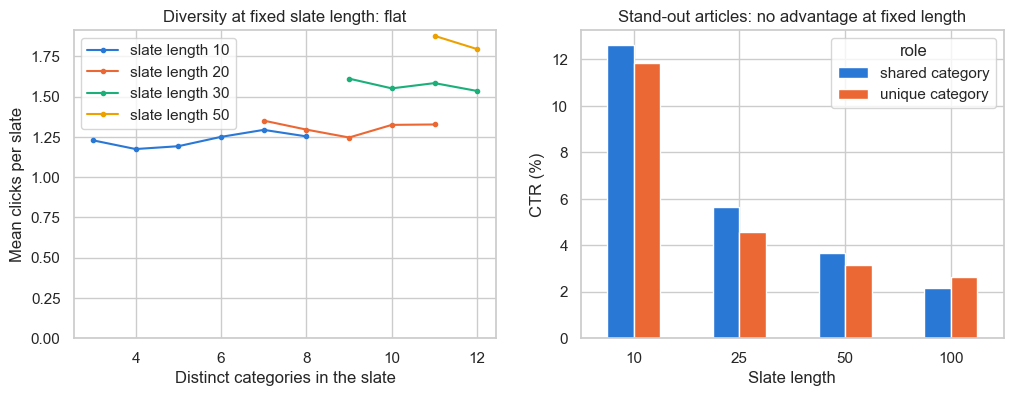

In [16]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for Lf, g in fixed_div.groupby("slate_len"):
    ax[0].plot(g.n_cats, g.mean_clicks, marker="o", ms=3, label=f"slate length {Lf}")
ax[0].set(
    ylim=(0, None),
    xlabel="Distinct categories in the slate",
    ylabel="Mean clicks per slate",
)
ax[0].set_title("Diversity at fixed slate length: flat")
ax[0].legend()
role_ctr.plot(kind="bar", ax=ax[1], rot=0)
ax[1].set(
    xlabel="Slate length",
    ylabel="CTR (%)",
    title="Stand-out articles: no advantage at fixed length",
)
plt.savefig(FIG_DIR / "imp_06_slate_composition.png", dpi=150, bbox_inches="tight")
plt.show()
del cc, slate_cat, per_slate

# Summary

| Finding | Decision |
|---|---|
| Every impression has a click; CTR ≈ 1 / slate length | drop `slate_len`; evaluate per impression; CTR is a within-log yardstick |
| Position carries no display-rank information | drop `position`; no position-bias correction |
| Labels exist only for shown pairs; 69% of the news file is never a candidate | unobserved ≠ negative; retrieval scored against known clicks only |
| 22.9 negatives per positive; K = 4 discards ≥ 84% | keep K = 4, report the discarded share, K = 8 / 16 sensitivity |
| Re-shown passed-over articles are clicked less (2.6% vs 4.4%) | time-causal `prior_exposure_count` feature |
| Diversity and stand-out effects vanish at fixed slate length | slate-context features low priority |